# Absolute and relative sea-level change

**Indicator:** rate (mm/yr) and magnitude (cm) of sea-level change from satellite altimetry (absolute) and from the tide gauge (relative), and the sensitivity of sea level to ENSO.

```{glue:figure} trend_fig
:scale: 50%
:align: right
```

Over {glue:text}`period_label`, absolute sea level near the {glue:text}`station` tide gauge rose by {glue:text}`delta_cm_altimetry:.1f` cm ({glue:text}`trend_mmyr_altimetry:.2f` mm/yr), while the tide gauge measured a relative rise of {glue:text}`delta_cm_tide_gauge:.1f` cm ({glue:text}`trend_mmyr_tide_gauge:.2f` mm/yr). Averaged over the {glue:text}`country` EEZ, altimetry gives {glue:text}`eez_rate_mmyr:.2f` mm/yr. For comparison, the satellite-era global-mean rate is about 3.3 mm/yr since 1993 and has accelerated to more than 4 mm/yr in the last decade.

Absolute sea level is the height of the sea surface relative to a reference ellipsoid, measured here by the Copernicus Marine Service (CMEMS) global L4 gridded sea-level anomalies. Relative sea level is measured by a tide gauge with respect to the land on which it stands. Differences between the two arise mainly from vertical land motion, but also from local oceanographic processes and from comparing a point measurement with a ~12 km grid cell.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from myst_nb import glue

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level.py).')
sys.path.insert(0, str(repo_root / 'functions'))

from data_downloaders import download_oni_index, download_uhslc_data
from sea_level import (
    ALTIMETRY_REFERENCE_PERIOD, ONI_URL, build_enso_summary_table, build_output_filename,
    build_site_tag, build_sl_magnitude_results, eez_bounds_360, eez_mask, load_site_config,
    process_trend_with_nan, resolve_eez, save_dict_json, save_table_to_csv, sea_level_config_path,
    station_attr, station_series,
)
from sea_level_plotting import (
    plot_combined_trends, plot_enso_scatter, plot_series_with_trend, plot_sl_change_map,
    plot_station_vs_grid_map,
)

## 1. Configuration

In [3]:
site_key = 'Palau'  # sea-level configuration written by 00_sea_level_setup.ipynb
site_cfg = load_site_config(sea_level_config_path(repo_root, site_key))

country = site_cfg['country']
uhslc_id = int(site_cfg['selected_uhslc_id'])
station = site_cfg['station']
station_lon, station_lat = float(site_cfg['station_lon']), float(site_cfg['station_lat'])
start_date = pd.Timestamp(site_cfg['start_date'])
end_date = pd.Timestamp(site_cfg['end_date'])
sea_level_dir = repo_root / site_cfg['sea_level_data_dir']
eez, eez_geometry = resolve_eez(country, repo_root / site_cfg['eez_file'])

site_name = site_cfg['site_name']
site_tag = build_site_tag(site_name, station_lon, station_lat)
fig_dir = repo_root / 'outputs' / 'figures' / site_tag
tab_dir = repo_root / 'outputs' / 'tables' / site_tag
matrix_dir = repo_root / 'matrix_cc' / 'figures'
for directory in (fig_dir, tab_dir, matrix_dir):
    directory.mkdir(parents=True, exist_ok=True)

def out(name, ext='png'):
    return build_output_filename(name, site_name, station_lon, station_lat, ext=ext)

glue('station', station, display=False)
glue('country', country, display=False)
print(f'{station}, {country} (UHSLC {uhslc_id:03d}); analysis period {start_date:%Y-%m-%d} to {end_date:%Y-%m-%d}')
print(f'Outputs: {fig_dir.relative_to(repo_root)} and {tab_dir.relative_to(repo_root)}')

Malakal, Palau (UHSLC 007); analysis period 1993-01-01 to 2024-12-31
Outputs: outputs/figures/palau_uhslc007_lat7p329_lon134p450 and outputs/tables/palau_uhslc007_lat7p329_lon134p450


## 2. Data

- **Satellite altimetry:** CMEMS `SEALEVEL_GLO_PHY_L4_MY_008_047`, daily 0.125° sea-level anomaly (`sla`, m) relative to the 1993–2012 mean sea surface ([doi:10.48670/moi-00148](https://doi.org/10.48670/moi-00148)). The file is prepared by the setup notebook.
- **Tide gauge:** UHSLC Fast Delivery daily mean sea level (mm, station datum).
- **EEZ:** the selected country's polygon from `data/regional/Pacific_EEZs`.

In [4]:
cmems_path = repo_root / site_cfg['cmems_file']
if not cmems_path.exists():
    raise FileNotFoundError(f'{cmems_path} not found — run 00_sea_level_setup.ipynb first.')
west, east, south, north = site_cfg['cmems_bounds']
ds = xr.open_dataset(cmems_path, chunks={'time': 366})
ds = ds.assign_coords(longitude=ds.longitude % 360).sortby('longitude')
sla = ds['sla'].sel(time=slice(start_date, end_date), longitude=slice(west, east), latitude=slice(south, north))

rsl = download_uhslc_data(sea_level_dir, uhslc_id, 'daily')
print(f"CMEMS: {cmems_path.name}, {sla.sizes['latitude']} x {sla.sizes['longitude']} cells, "
      f"{str(sla.time.values[0])[:10]} to {str(sla.time.values[-1])[:10]}")
print(f"UHSLC: {station_attr(rsl, 'station_name')} — {str(rsl.time.values[0])[:10]} to {str(rsl.time.values[-1])[:10]}")

CMEMS: cmems_L4_SSH_0.125deg_1993_2025.nc, 95 x 76 cells, 1993-01-01 to 2024-12-31
UHSLC: Malakal — 1969-05-19 to 2026-05-31


## 3. Common reference and nearest altimetry cell

Both records are expressed relative to their own mean over the altimetry reference period (1993–2012), so that the two series share a zero line. Linear trends do not depend on this choice. The tide gauge is compared with the nearest altimetry grid cell that contains data.

In [5]:
ref_start, ref_end = ALTIMETRY_REFERENCE_PERIOD
tg = station_series(rsl) / 1000.0  # m, station datum
rsl_daily = (tg - tg.sel(time=slice(ref_start, ref_end)).mean()).sel(time=slice(start_date, end_date)).dropna('time')
rsl_daily.attrs['units'] = 'm'

ocean = sla.isel(time=slice(0, 60)).notnull().any('time').compute()
dist = np.hypot(sla.longitude - station_lon % 360, sla.latitude - station_lat).where(ocean).transpose('latitude', 'longitude')
iy, ix = np.unravel_index(int(np.nanargmin(dist.values)), dist.shape)
sla_nearest = sla.isel(latitude=iy, longitude=ix).load()
sla_nearest = sla_nearest - sla_nearest.sel(time=slice(ref_start, ref_end)).mean()
alt_lat, alt_lon = float(sla_nearest.latitude), float(sla_nearest.longitude)
alt_label = f"{abs(alt_lat):.3f}°{'N' if alt_lat >= 0 else 'S'}, {alt_lon:.3f}°E"
print(f'Nearest altimetry cell: {alt_label} ({111 * float(dist.min()):.1f} km from the gauge)')
glue('period_label', f'{start_date:%Y}–{end_date:%Y}', display=False)

Nearest altimetry cell: 7.312°N, 134.438°E (2.3 km from the gauge)


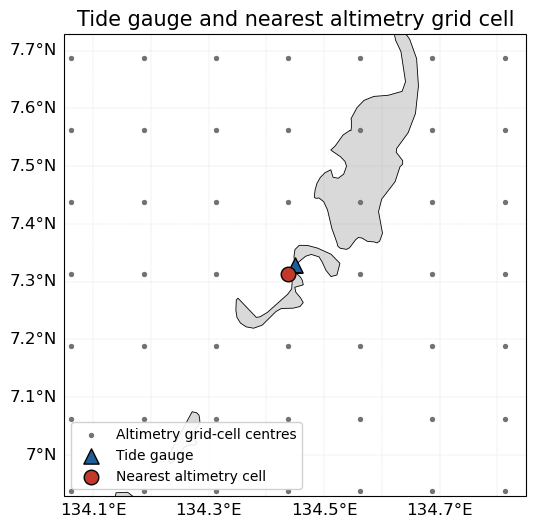

In [6]:
fig, ax = plot_station_vs_grid_map(station_lon, station_lat, alt_lon, alt_lat, sla.isel(time=0))
plt.show()

## 4. Absolute sea-level change across the EEZ

The trend is fitted to monthly means at every grid cell. The map shows the fitted change over the analysis period; the circle shows the relative change at the tide gauge on the same colour scale.

EEZ-mean absolute trend: 5.04 ± 1.06 mm/yr (16.1 cm over 1993–2024)


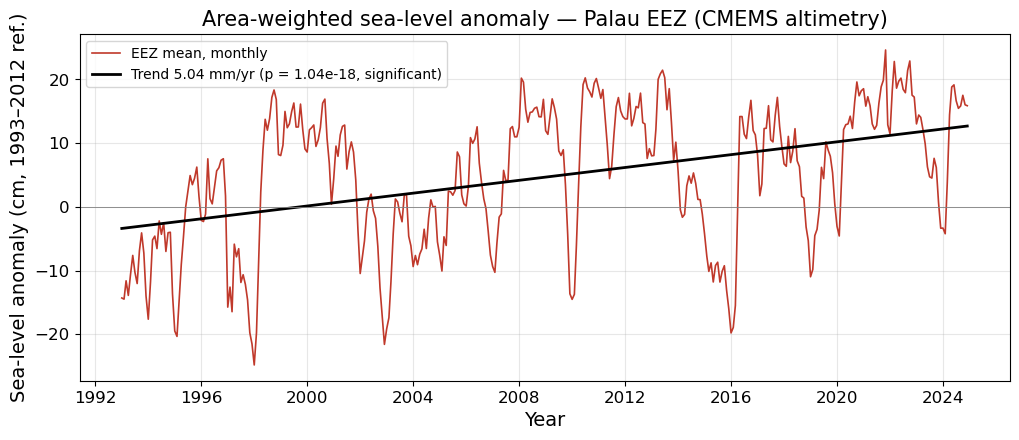

In [7]:
sla_monthly = sla.resample(time='MS').mean().load()
trend_mag_grid, _, trend_rate_grid, p_grid, _ = process_trend_with_nan(sla_monthly)

mask = eez_mask(eez_geometry, sla_monthly.longitude, sla_monthly.latitude)
weights = np.cos(np.deg2rad(sla_monthly.latitude)).broadcast_like(mask).where(mask, 0)
eez_series = sla_monthly.weighted(weights).mean(('latitude', 'longitude'))
eez_mag, eez_line, eez_rate, eez_p, eez_err = process_trend_with_nan(eez_series)
glue('eez_rate_mmyr', 1000 * float(eez_rate), display=False)
print(f'EEZ-mean absolute trend: {1000 * float(eez_rate):.2f} ± {1000 * 1.96 * float(eez_err):.2f} mm/yr '
      f'({100 * float(eez_mag):.1f} cm over {start_date:%Y}–{end_date:%Y})')

fig, ax, _ = plot_series_with_trend(
    100 * eez_series.to_series(),
    f'Area-weighted sea-level anomaly — {country} EEZ (CMEMS altimetry)',
    ylabel='Sea-level anomaly (cm, 1993–2012 ref.)',
    label='EEZ mean, monthly',
)
fig.savefig(fig_dir / out('SL_eez_mean_timeseries'), dpi=150, bbox_inches='tight')
plt.show()

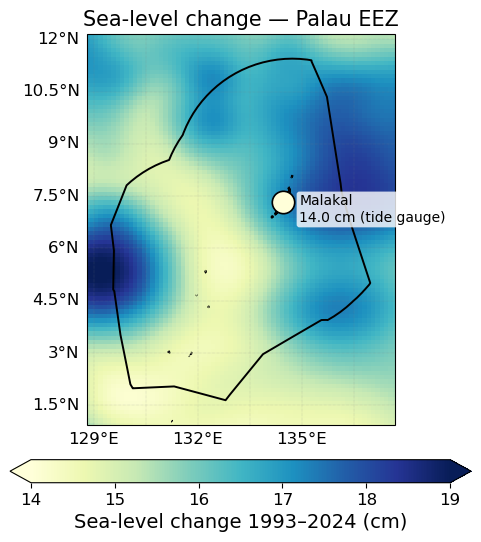

In [8]:
trend_mag_rsl, trend_line_rsl, trend_rate_rsl, p_rsl, err_rsl = process_trend_with_nan(rsl_daily)
trend_mag_asl, trend_line_asl, trend_rate_asl, p_asl, err_asl = process_trend_with_nan(sla_nearest)

w_, e_, s_, n_ = eez_bounds_360(eez_geometry)
xlims, ylims = (w_ - 0.7, e_ + 0.7), (s_ - 0.7, n_ + 0.7)
change_cm = 100 * trend_mag_grid
vmin, vmax = np.floor(np.nanpercentile(change_cm.where(mask), [2, 98]))
vmax = max(vmax + 1, float(np.ceil(100 * float(trend_mag_rsl))) + 1)
fig, ax = plot_sl_change_map(
    change_cm, eez, xlims, ylims, vmin, vmax,
    label=f'Sea-level change {start_date:%Y}–{end_date:%Y} (cm)',
    title=f'Sea-level change — {country} EEZ',
    station=(station_lon, station_lat, 100 * float(trend_mag_rsl), station),
)
glue('mag_fig', fig, display=False)
fig.savefig(fig_dir / out('SL_magnitude_map'), dpi=300, bbox_inches='tight')
fig.savefig(matrix_dir / out('F10_SeaLevel_map'), dpi=300, bbox_inches='tight')

```{glue:figure} mag_fig
:name: "fig-mag"

Absolute sea-level change from altimetry over the {glue:text}`country` EEZ (shading) and relative change at the {glue:text}`station` tide gauge (circle), {glue:text}`period_label`.
```

## 5. Absolute versus relative change at the tide gauge

Daily records are used for both sources. The legend reports the trend rate; lines are solid when the trend is significant at the 5% level and dashed otherwise. Because daily residuals are strongly autocorrelated, the p-values are descriptive.

In [9]:
SL_magnitude_results, sl_glue_values = build_sl_magnitude_results(
    trend_rate_asl, trend_rate_rsl, trend_mag_asl, trend_mag_rsl,
    alt_lat, alt_lon, station_attr(rsl, 'lat'), station_attr(rsl, 'lon'),
    f'{start_date:%Y-%m-%d}', f'{end_date:%Y-%m-%d}',
)
for key, value in sl_glue_values.items():
    glue(key, value, display=False)
save_table_to_csv(SL_magnitude_results, tab_dir, out('SL_magnitude_results', 'csv'), index=True)
SL_magnitude_results

,Rate (mm/yr),Rate (in/yr),Change 1993-2024 (cm),Change 1993-2024 (in),Latitude,Longitude
Absolute (altimetry),5.38,0.21,17.20,6.77,7.31,134.44
Relative (tide gauge),4.37,0.17,13.99,5.51,7.33,134.45


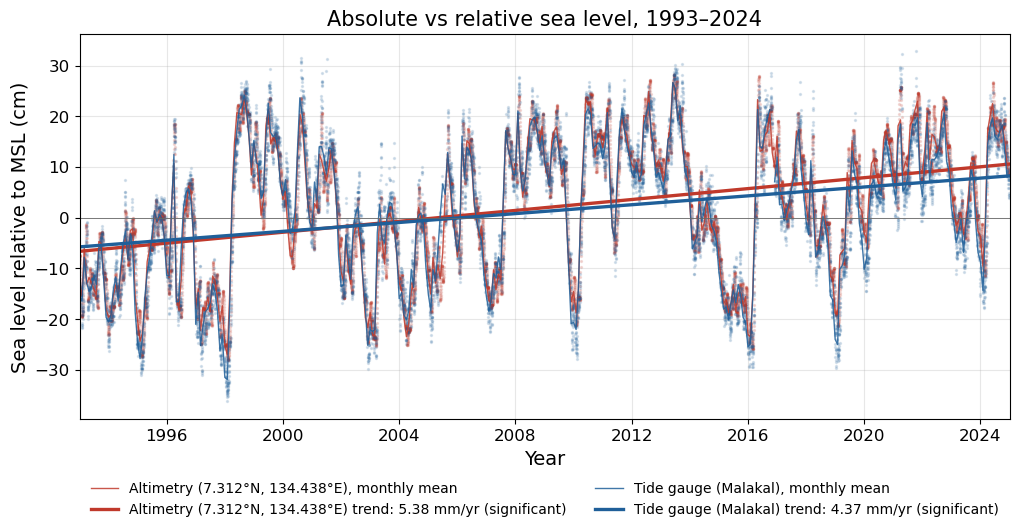

In [10]:
fig, ax = plot_combined_trends(
    sla_nearest, trend_line_asl, trend_rate_asl, float(p_asl),
    rsl_daily, trend_line_rsl, trend_rate_rsl, float(p_rsl),
    alt_label, station, start_date, end_date,
)
glue('trend_fig', fig, display=False)
fig.savefig(fig_dir / out('SL_magnitude_timeseries'), dpi=300, bbox_inches='tight')
fig.savefig(matrix_dir / out('F10_SeaLevel_trends'), dpi=300, bbox_inches='tight')

```{glue:figure} trend_fig
:name: "trend_fig"

Absolute sea level from altimetry (red) and relative sea level at the {glue:text}`station` tide gauge (blue), {glue:text}`period_label`, with linear trends.
```

The difference between the two rates (altimetry minus tide gauge) approximates vertical land motion at the gauge; a positive value indicates land uplift and a negative value subsidence. It also includes the mismatch between a grid-cell average and a harbour measurement, so it should not be interpreted as a geodetic measurement.

## 6. ENSO influence on sea level

The tide-gauge series is detrended and its mean seasonal cycle removed before comparison with the Oceanic Niño Index (ONI). In the western tropical Pacific, sea level is typically lower during El Niño and higher during La Niña.

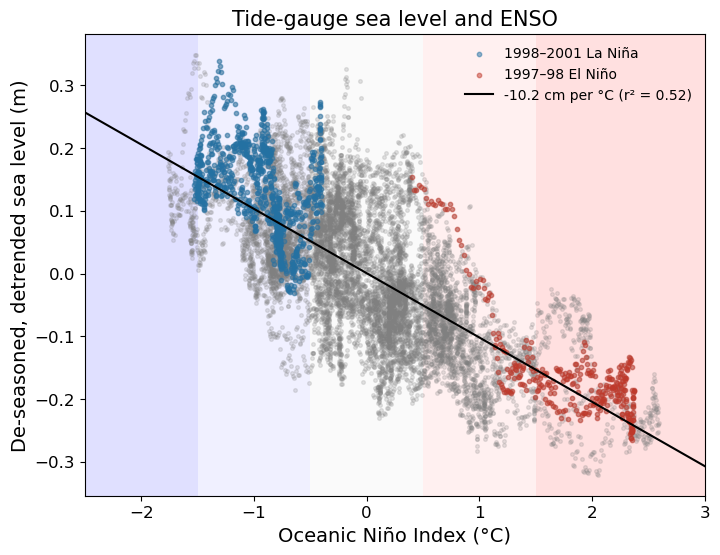

Metric,Value
Sensitivity to ONI,-10.2 cm per °C
Correlation (r),-0.72
Explained variance (r²),0.52
p-value (descriptive),0
"Mean anomaly, 1997–98 El Niño",-15.5 cm
"Mean anomaly, 1998–2001 La Niña",13.4 cm


In [11]:
oni = download_oni_index(ONI_URL)
detrended_rsl = rsl_daily - trend_line_rsl
deseasoned_rsl = detrended_rsl.groupby('time.dayofyear') - detrended_rsl.groupby('time.dayofyear').mean('time')
oni_daily = oni.resample('D').interpolate('linear').reindex(deseasoned_rsl.time.values, method='nearest')

fig, ax, slope, intercept, r_value, p_value, std_err, nina_1998, nino_1997 = plot_enso_scatter(oni_daily, deseasoned_rsl)
fig.savefig(fig_dir / out('SL_ONI_scatter'), dpi=300, bbox_inches='tight')
plt.show()

summary_table, styled = build_enso_summary_table(slope, nino_1997, nina_1998, r_value, p_value)
save_table_to_csv(summary_table, tab_dir, out('ENSO_SL_influence_summary', 'csv'))
styled

## 7. Summary metrics

In [12]:
summary_metrics = {
    'country': country,
    'station': station,
    'uhslc_id': uhslc_id,
    'period_start': f'{start_date:%Y-%m-%d}',
    'period_end': f'{end_date:%Y-%m-%d}',
    'altimetry_cell_lat': alt_lat,
    'altimetry_cell_lon': alt_lon,
    'altimetry_trend_mm_yr': 1000 * float(trend_rate_asl),
    'tide_gauge_trend_mm_yr': 1000 * float(trend_rate_rsl),
    'tide_gauge_trend_se_mm_yr': 1000 * float(err_rsl),
    'altimetry_minus_tide_gauge_mm_yr': 1000 * float(trend_rate_asl - trend_rate_rsl),
    'altimetry_change_cm': 100 * float(trend_mag_asl),
    'tide_gauge_change_cm': 100 * float(trend_mag_rsl),
    'eez_mean_trend_mm_yr': 1000 * float(eez_rate),
    'eez_mean_trend_se_mm_yr': 1000 * float(eez_err),
    'oni_sensitivity_cm_per_degC': 100 * float(slope),
    'oni_r': float(r_value),
}
save_dict_json(summary_metrics, tab_dir, out('SL_trend_summary_metrics', 'json'))
pd.Series(summary_metrics).to_frame('value')

,value
country,Palau
station,Malakal
uhslc_id,7
period_start,1993-01-01
period_end,2024-12-31
altimetry_cell_lat,7.3125
altimetry_cell_lon,134.4375
altimetry_trend_mm_yr,5.375872
tide_gauge_trend_mm_yr,4.373151
tide_gauge_trend_se_mm_yr,0.129346


## Interpretation and reproducibility notes

- **Sources:** CMEMS L4 DUACS multi-mission altimetry (absolute) and UHSLC Fast Delivery tide-gauge data (relative). Fast Delivery data are only level-1 quality controlled.
- **Reference:** both series are shown relative to their 1993–2012 mean; trends are independent of the reference.
- **Trends** are ordinary least-squares fits and are descriptive: residuals are autocorrelated and ENSO variability is large in the western Pacific, so short periods can give very different rates.
- **Absolute vs relative:** the difference approximates vertical land motion plus representativeness error between a ~12 km grid cell and a harbour gauge.
- **EEZ mean:** grid cells are weighted by the cosine of latitude and masked to the EEZ polygon; it is a spatial average, not a station value.